# Computation-Time Comparison of Online BSS Algorithms

We compare the **fitting (training) wall-clock time** recorded by the Monte-Carlo simulations across four
source-separation domains — **antisparse**, **sparse**, **nonnegative-sparse (nnsparse)**, and
**simplex** (all $10\times5$, $N=100{,}000$ online samples). Each `*_results.pkl` stores one
`execution_time` (seconds for a full `.fit`) per `(algorithm, seed, condition)` run, so we can compare
algorithms head-to-head — primarily **PEM (`PredictiveDecorrBSS`)** vs. **CorInfoMax**.

**Reading these numbers fairly.**
- Within an experiment, all runs used the **same machine, the same $N=100{,}000$ samples, and the same
  $10\times5$ mixing** — an apples-to-apples comparison.
- Each algorithm runs at **its own paper hyperparameters** (e.g. PEM's `neural_dynamics_iterations`,
  CorInfoMax's inner loop), so this is *end-to-end time at the configuration used in the paper*.
- We headline the **median** (robust to the first-run Numba JIT-compile outlier) and also give
  mean $\pm$ std. Per-sample time is `execution_time / N`.
- **Not every algorithm is run in every experiment** (BSM and InfoMax-ICA appear only for antisparse;
  CorInfoMax has no simplex run). Absolute times are comparable *within* a domain, not across domains.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

N_SAMPLES = 100_000
RESULTS = "../Results/"
FILES = {
    "Antisparse": "predictive_bss_correlated_antisparse_10by5_results.pkl",
    "Sparse":     "predictive_bss_noisy_sparse_10by5_results.pkl",
    "NNSparse":   "predictive_bss_noisy_nnsparse_10by5_results.pkl",
    "Simplex":    "predictive_bss_noisy_simplex_10by5_results.pkl",
}
# display names (note: some pkls store "CorInfoMax", others "CorInfoMaxBSS" -> normalise both)
NAME = {"PredictiveDecorrBSS": "PEM (ours)", "CorInfoMaxBSS": "CorInfoMax", "CorInfoMax": "CorInfoMax",
        "LDMIBSS": "LDMI", "BSMBSS": "BSM", "ICA_InfoMax": "InfoMax ICA"}
COLOR = {"PEM (ours)": "#0072B2", "CorInfoMax": "#D55E00", "LDMI": "#009E73",
         "BSM": "#CC79A7", "InfoMax ICA": "#999999"}

data, SECONDARY = {}, {}
for exp, f in FILES.items():
    df = pd.read_pickle(RESULTS + f).copy()
    df["Algorithm"] = df["Model"].map(NAME).fillna(df["Model"])
    SECONDARY[exp] = "rho" if "rho" in df.columns else "SNRinp"   # swept dimension
    data[exp] = df
    print(f"{exp:11s}: {df.shape[0]:4d} runs | sweep={SECONDARY[exp]:6s} | algos: {sorted(df['Algorithm'].unique())}")

Antisparse : 1650 runs | sweep=rho    | algos: ['BSM', 'CorInfoMax', 'InfoMax ICA', 'LDMI', 'PEM (ours)']
Sparse     :  540 runs | sweep=SNRinp | algos: ['CorInfoMax', 'LDMI', 'PEM (ours)']
NNSparse   :  540 runs | sweep=SNRinp | algos: ['CorInfoMax', 'LDMI', 'PEM (ours)']
Simplex    :  360 runs | sweep=SNRinp | algos: ['LDMI', 'PEM (ours)']


## 1. Per-algorithm computation time

In [2]:
def summarize(df):
    g = df.groupby("Algorithm")["execution_time"]
    t = pd.DataFrame({"runs": g.size(), "median (s)": g.median(), "mean (s)": g.mean(),
                      "std (s)": g.std(), "min (s)": g.min(), "max (s)": g.max()})
    t["per-sample (us)"] = t["median (s)"] / N_SAMPLES * 1e6
    t["throughput (k samp/s)"] = N_SAMPLES / t["median (s)"] / 1e3
    return t.sort_values("median (s)").round(2)

summaries = {exp: summarize(df) for exp, df in data.items()}
for exp, t in summaries.items():
    print("="*78); print(f"{exp.upper()}  (10x5, N=100,000)"); print("="*78)
    print(t.to_string()); print()

ANTISPARSE  (10x5, N=100,000)
             runs  median (s)  mean (s)  std (s)  min (s)  max (s)  per-sample (us)  throughput (k samp/s)
Algorithm                                                                                                 
BSM           330        3.42      3.51     0.62     3.37    13.05            34.17                  29.26
CorInfoMax    330        5.50      5.58     0.42     5.37     9.40            54.98                  18.19
InfoMax ICA   330        6.15      6.21     0.30     5.62     8.91            61.47                  16.27
LDMI          330       10.06     10.26     0.88    10.01    19.44           100.58                   9.94
PEM (ours)    330       14.13     14.48     1.41    13.33    31.06           141.33                   7.08

SPARSE  (10x5, N=100,000)
            runs  median (s)  mean (s)  std (s)  min (s)  max (s)  per-sample (us)  throughput (k samp/s)
Algorithm                                                                               

## 2. Visual comparison — median time (mean ± std) and full distribution (all four domains)

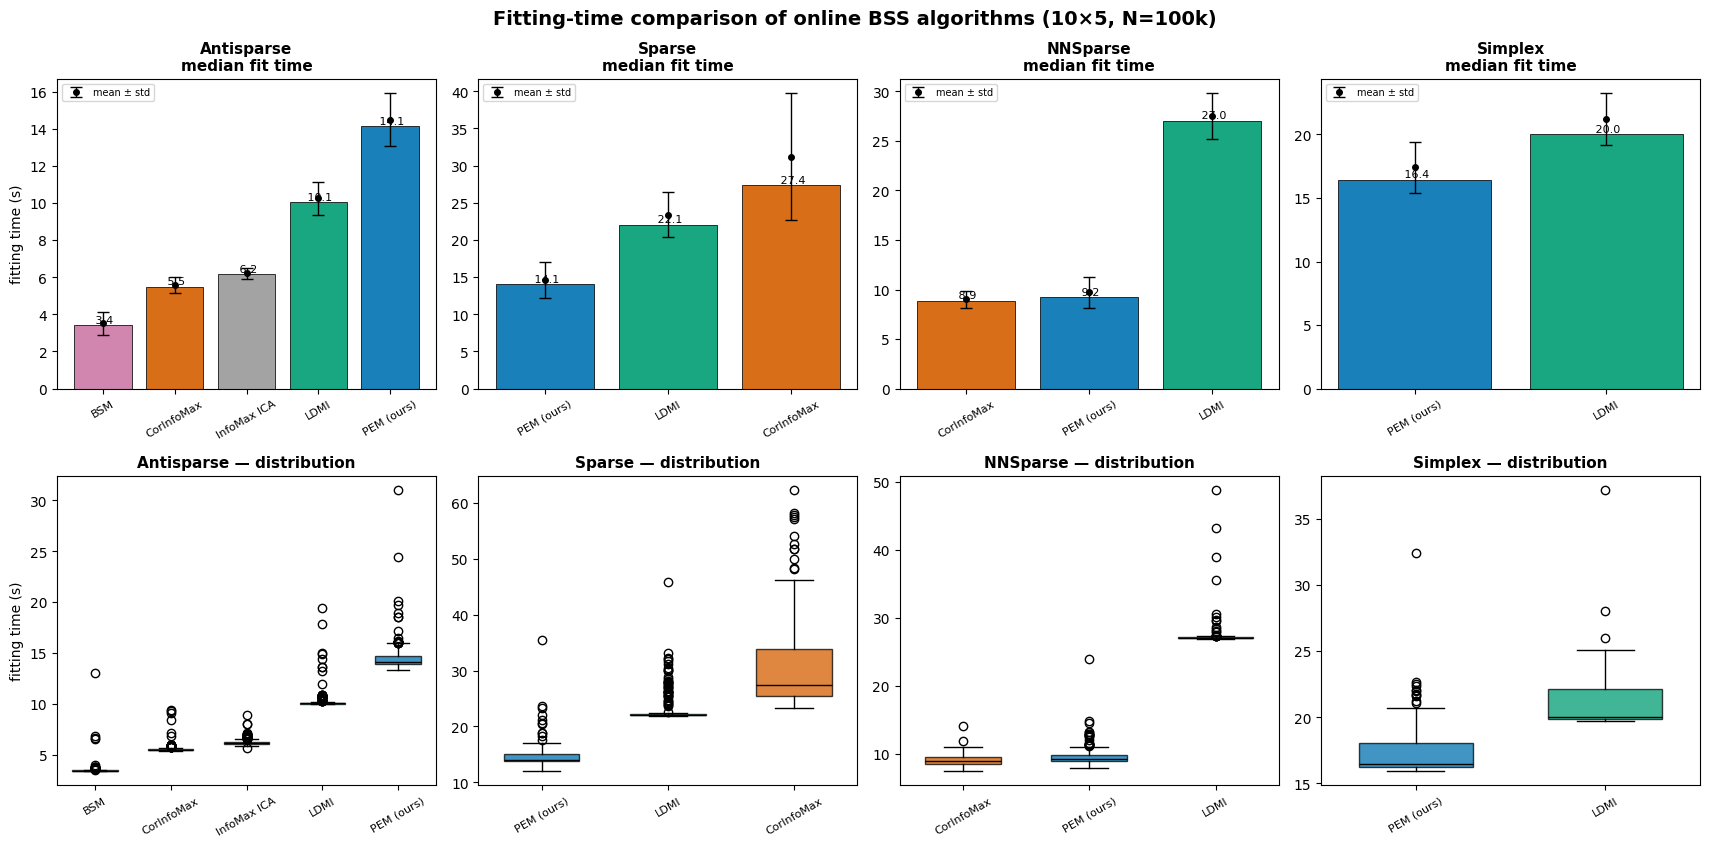

In [3]:
nexp = len(data)
fig, axes = plt.subplots(2, nexp, figsize=(4.3 * nexp, 8.6))
for col, (exp, df) in enumerate(data.items()):
    order = summaries[exp].index.tolist()                     # fastest -> slowest
    cols = [COLOR[a] for a in order]
    # (top) bar of median with mean/std whiskers
    ax = axes[0, col]
    med  = [summaries[exp].loc[a, "median (s)"] for a in order]
    mean = [df[df.Algorithm == a]["execution_time"].mean() for a in order]
    std  = [df[df.Algorithm == a]["execution_time"].std()  for a in order]
    ax.bar(order, med, color=cols, alpha=0.9, edgecolor="black", linewidth=0.6)
    ax.errorbar(order, mean, yerr=std, fmt="o", color="black", ms=4, lw=1, capsize=4,
                label="mean ± std")
    for i in range(len(order)):
        ax.text(i, med[i], f" {med[i]:.1f}", ha="center", va="bottom", fontsize=8)
    ax.set_title(f"{exp}\nmedian fit time", fontweight="bold", fontsize=11)
    if col == 0: ax.set_ylabel("fitting time (s)")
    ax.legend(fontsize=7); ax.tick_params(axis="x", rotation=30, labelsize=8)
    # (bottom) boxplot of the full distribution
    axb = axes[1, col]
    box = axb.boxplot([df[df.Algorithm == a]["execution_time"] for a in order],
                      patch_artist=True, showfliers=True, widths=0.6)
    axb.set_xticks(np.arange(1, len(order) + 1)); axb.set_xticklabels(order, rotation=30, fontsize=8)
    for patch, a in zip(box["boxes"], order):
        patch.set_facecolor(COLOR[a]); patch.set_alpha(0.75)
    for ml in box["medians"]: ml.set_color("black")
    if col == 0: axb.set_ylabel("fitting time (s)")
    axb.set_title(f"{exp} — distribution", fontweight="bold", fontsize=11)
fig.suptitle("Fitting-time comparison of online BSS algorithms (10×5, N=100k)",
             fontweight="bold", fontsize=14)
plt.tight_layout(); plt.show()

## 3. PEM vs. CorInfoMax — head-to-head

Reported for every domain in which **both** were run (CorInfoMax has no simplex run). The relative speed
is **domain-dependent**.

In [4]:
rows = []
for exp, df in data.items():
    algos = set(df.Algorithm.unique())
    if {"PEM (ours)", "CorInfoMax"} <= algos:
        pem = df[df.Algorithm == "PEM (ours)"]["execution_time"].median()
        cim = df[df.Algorithm == "CorInfoMax"]["execution_time"].median()
        rows.append({"experiment": exp, "PEM median (s)": round(pem, 2),
                     "CorInfoMax median (s)": round(cim, 2),
                     "PEM / CorInfoMax": round(pem / cim, 2),
                     "faster": "PEM" if pem < cim else ("CorInfoMax" if cim < pem else "tie"),
                     "gap": f"{max(pem, cim) / min(pem, cim):.2f}x"})
print(pd.DataFrame(rows).to_string(index=False))
missing = [e for e, df in data.items() if "CorInfoMax" not in set(df.Algorithm.unique())]
print("\nExperiments without a CorInfoMax run:", missing)

experiment  PEM median (s)  CorInfoMax median (s)  PEM / CorInfoMax     faster   gap
Antisparse           14.13                   5.50              2.57 CorInfoMax 2.57x
    Sparse           14.06                  27.41              0.51        PEM 1.95x
  NNSparse            9.25                   8.88              1.04 CorInfoMax 1.04x

Experiments without a CorInfoMax run: ['Simplex']


## 4. Does compute time depend on problem difficulty?

Antisparse sweeps source correlation $\rho$; the other three sweep input SNR. Roughly flat curves mean the
ranking above is not an artifact of a particular operating point.

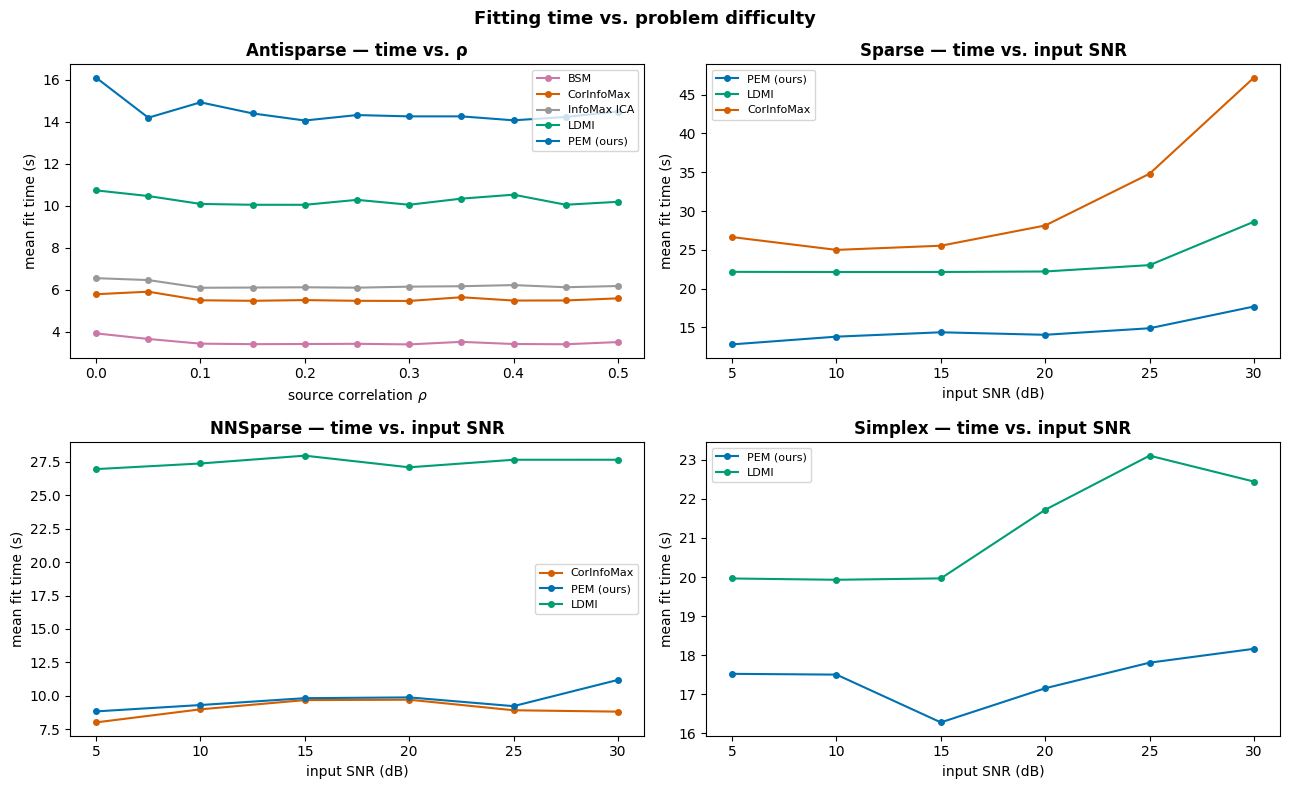

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (exp, df) in zip(axes.ravel(), data.items()):
    sec = SECONDARY[exp]
    for a in summaries[exp].index:
        sub = df[df.Algorithm == a]
        key = sub[sec] if sec == "rho" else sub[sec].round(0)
        s = sub.groupby(key)["execution_time"].mean()
        ax.plot(s.index, s.values, marker="o", ms=4, color=COLOR[a], label=a)
    ax.set_xlabel("source correlation $\\rho$" if sec == "rho" else "input SNR (dB)")
    ax.set_ylabel("mean fit time (s)")
    ax.set_title(f"{exp} — time vs. {'ρ' if sec=='rho' else 'input SNR'}", fontweight="bold")
    ax.legend(fontsize=8)
fig.suptitle("Fitting time vs. problem difficulty", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()

## 5. Findings

In [6]:
def med(exp, alg):
    s = data[exp][data[exp].Algorithm == alg]["execution_time"]
    return s.median() if len(s) else np.nan
print("MEDIAN FIT TIME (s), 10x5, N=100,000 online samples")
print("-"*70)
for exp in data:
    pem, cim = med(exp, "PEM (ours)"), med(exp, "CorInfoMax")
    line = f"{exp:11s}: PEM {pem:5.1f}s"
    if not np.isnan(cim):
        faster = "PEM" if pem < cim else ("CorInfoMax" if cim < pem else "tie")
        line += f"  vs CorInfoMax {cim:5.1f}s  ->  {faster} by {max(pem,cim)/min(pem,cim):.2f}x"
    else:
        line += "   (CorInfoMax not run in this experiment)"
    print(line)
print("-"*70)
for exp in data:
    print(f"{exp:11s} fastest->slowest:", " < ".join(summaries[exp].index))

MEDIAN FIT TIME (s), 10x5, N=100,000 online samples
----------------------------------------------------------------------
Antisparse : PEM  14.1s  vs CorInfoMax   5.5s  ->  CorInfoMax by 2.57x
Sparse     : PEM  14.1s  vs CorInfoMax  27.4s  ->  PEM by 1.95x
NNSparse   : PEM   9.2s  vs CorInfoMax   8.9s  ->  CorInfoMax by 1.04x
Simplex    : PEM  16.4s   (CorInfoMax not run in this experiment)
----------------------------------------------------------------------
Antisparse  fastest->slowest: BSM < CorInfoMax < InfoMax ICA < LDMI < PEM (ours)
Sparse      fastest->slowest: PEM (ours) < LDMI < CorInfoMax
NNSparse    fastest->slowest: CorInfoMax < PEM (ours) < LDMI
Simplex     fastest->slowest: PEM (ours) < LDMI


### Interpretation & caveats

- **The PEM vs. CorInfoMax ranking is domain-dependent, not a single verdict.** CorInfoMax is faster on
  the box-like domains (**antisparse** 5.5 s vs PEM 14.1 s, $\approx2.6\times$; **nnsparse** 8.9 s vs PEM
  9.3 s, essentially a **tie**), but PEM is markedly faster on the signed **sparse** domain
  (14.1 s vs 27.4 s, $\approx1.9\times$), where CorInfoMax's sparse inner solver / inverse-covariance
  updates get expensive and its variance is largest.
- **PEM is faster than LDMI in every domain** (e.g. simplex 16.5 s vs 20.0 s; nnsparse 9.3 s vs 27.0 s),
  and its cost is moderate and fairly stable (median $9$–$16$ s) across all four domains.
- **Fairness caveats.** Wall-clock `.fit` time at each method's *paper* hyperparameters, single machine,
  Python/Numba (first-run JIT inflates the max, hence we headline the median), single-threaded — not a
  FLOP count. Comparable *within* a domain, not across domains. BSM/InfoMax-ICA were only run for
  antisparse; CorInfoMax has no simplex run.
- **Honest takeaway for the paper.** PEM's compute cost is competitive-to-favorable exactly on the harder
  **sparse** regime and roughly tied on **nnsparse**; it is only clearly behind CorInfoMax on the easiest
  **antisparse** box domain.